# Project 1 — Rational AG initiation: valuation notebook
Runs the model in `src/model.py` (the Excel workbook `model/rational_model.xlsx` reproduces it with formulas and is
checked by `src/check_workbook.py`), and produces the tables and charts used in the report.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common.plotting import PALETTE, setup, source
from src import model as M
from src.comps import comps_table

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SRC_AR = "Source: Rational annual reports 2016–2025, H1 2026 report; author's forecasts (2026–2035)."

## 1. Market inputs and cost of capital

In [2]:
MK = M.market_inputs()
MK

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


{'rf': 0.0355,
 'rf_date': '2026-10-07',
 'erp': 0.042,
 'erp_month': '2026-10-01',
 'beta_raw': 1.72565210772655,
 'beta_se': 0.19046131154680226,
 'beta_r2': 0.5859819469426565,
 'beta_months': 60,
 'beta_blume': 1.4861869121767888,
 'ke': 0.09791985031142514,
 'price': 566.5,
 'price_date': '2026-10-07'}

## 2. History

In [3]:
H, RH, PH = M.history(), M.regions_history(), M.products_history()
s = H.loc["Sales revenues"]
HIST = pd.DataFrame({"Sales": s, "Growth": s.pct_change(), "Gross margin": H.loc["Gross profit"] / s, "EBIT": H.loc["EBIT"],
                     "EBIT margin": H.loc["EBIT"] / s, "Net profit": H.loc["Net profit"], "EPS (EUR)": H.loc["Net profit"] / M.SHARES,
                     "DPS paid in year (EUR)": -H.loc["Dividends paid"] / M.SHARES, "CFO": H.loc["CFO"], "Capex": -H.loc["Capex"],
                     "FCF (CFO − capex)": H.loc["CFO"] + H.loc["Capex"], "iVario share": PH["iVario"] / s,
                     "Cash + deposits": H.loc["Cash"] + H.loc["Other current financial assets"].fillna(0) + H.loc["Fixed deposits > 3 months"].fillna(0),
                     "Equity": H.loc["Equity"]})
HIST.T.round(3)

,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Sales,613.010,702.100,777.859,843.633,649.587,779.734,1022.345,1125.838,1193.529,1259.558
Growth,NaN,0.145,0.108,0.085,-0.230,0.200,0.311,0.101,0.060,0.055
Gross margin,0.618,0.607,0.587,0.590,0.554,0.551,0.553,0.567,0.592,0.590
EBIT,166.511,187.568,205.012,223.375,106.806,160.134,237.510,277.001,314.198,332.552
EBIT margin,0.272,0.267,0.264,0.265,0.164,0.205,0.232,0.246,0.263,0.264
Net profit,127.107,143.001,157.310,171.590,80.096,123.663,185.722,215.762,250.530,253.847
EPS (EUR),11.179,12.577,13.836,15.091,7.045,10.876,16.334,18.976,22.034,22.326
DPS paid in year (EUR),7.500,10.000,11.000,9.500,5.700,4.800,10.000,13.500,13.500,15.000
CFO,129.490,145.936,144.326,198.638,92.690,171.710,160.618,258.345,283.064,253.079
Capex,24.592,34.224,46.166,40.674,33.397,25.820,37.184,34.632,31.618,33.704


## 3. Forecasts and valuation

In [4]:
FC = {s_: M.forecast(s_) for s_ in M.WEIGHTS}
VAL, TP = M.valuation(MK["ke"])
RATING, UP = M.rating(TP, MK["price"])
IMPLIED_KE = M.implied_ke(MK["price"])
REVERSE = M.reverse_dcf(MK["price"], MK["ke"])
print("Reverse DCF at the model's cost of equity:", {k: round(v, 4) for k, v in REVERSE.items()})
print(f"Weighted target €{TP:.2f}, price €{MK['price']:.2f}, {UP:+.1%} -> {RATING}; ke {MK['ke']:.2%}; price implies ke {IMPLIED_KE:.2%}")
SUMMARY = pd.DataFrame({s_: {"Sales 2026": FC[s_][0].loc[2026, "Sales"], "Sales 2030": FC[s_][0].loc[2030, "Sales"],
                             "Sales 2035": FC[s_][0].loc[2035, "Sales"],
                             "Sales CAGR 2025–35": (FC[s_][0].loc[2035, "Sales"] / s[2025]) ** 0.1 - 1,
                             "EBIT 2026": FC[s_][0].loc[2026, "EBIT"], "EBIT 2027": FC[s_][0].loc[2027, "EBIT"],
                             "EBIT margin 2028+": FC[s_][0].loc[2030, "EBIT margin"],
                             "EV": VAL[s_]["ev"], "Equity value": VAL[s_]["equity"], "Value per share": VAL[s_]["value_per_share"],
                             "12-month target": VAL[s_]["target"], "TV share of EV": VAL[s_]["tv_share_of_ev"],
                             "Weight": M.WEIGHTS[s_]} for s_ in ["Bear", "Base", "Bull"]})
SUMMARY.round(3)

Reverse DCF at the model's cost of equity: {'growth_shift_2027_2030': 0.0898, 'ebit_margin_2027_on': 0.3809}
Weighted target €413.65, price €566.50, -27.0% -> Sell; ke 9.79%; price implies ke 7.24%


,Bear,Base,Bull
Sales 2026,1308.135,1333.326,1345.921
Sales 2030,1507.781,1722.615,1873.046
Sales 2035,1770.789,2142.798,2419.637
Sales CAGR 2025–35,0.035,0.055,0.067
EBIT 2026,327.034,339.998,349.940
EBIT 2027,325.217,369.503,394.607
EBIT margin 2028+,0.240,0.265,0.280
EV,3164.489,4077.601,4762.814
Equity value,3589.796,4502.908,5188.121
Value per share,315.725,396.034,456.299


In [5]:
BASE = FC["Base"][0]
EPS_PROXY = (BASE["NOPAT"] / M.SHARES)
CONS = {"Sales": {2026: 1350, 2027: 1454}, "EBIT": {2026: 349.0, 2027: 376.2}, "EPS": {2026: 23.98, 2027: 25.73}}
VS_CONS = pd.DataFrame({"Model sales": BASE.loc[[2026, 2027], "Sales"], "Consensus sales": pd.Series(CONS["Sales"]),
                        "Model EBIT": BASE.loc[[2026, 2027], "EBIT"], "Consensus EBIT": pd.Series(CONS["EBIT"])})
VS_CONS["EBIT vs consensus"] = VS_CONS["Model EBIT"] / VS_CONS["Consensus EBIT"] - 1
VS_CONS.round(3)

,Model sales,Consensus sales,Model EBIT,Consensus EBIT,EBIT vs consensus
2026,1333.326,1350,339.998,349.0,-0.026
2027,1421.164,1454,369.503,376.2,-0.018


In [6]:
grows, shifts = [0.01, 0.015, 0.02, 0.025, 0.03], [-0.01, -0.005, 0, 0.005, 0.01]
SENS = pd.DataFrame({g: {MK["ke"] + d: M.valuation(MK["ke"] + d, g)[1] for d in shifts} for g in grows})
SENS.index = [f"{x:.2%}" for x in SENS.index]; SENS.columns = [f"{g:.1%}" for g in SENS.columns]
SENS.round(0)

,1.0%,1.5%,2.0%,2.5%,3.0%
8.79%,433.0,449.0,467.0,489.0,514.0
9.29%,409.0,423.0,439.0,456.0,477.0
9.79%,389.0,400.0,414.0,429.0,446.0
10.29%,370.0,380.0,392.0,405.0,419.0
10.79%,354.0,363.0,373.0,383.0,396.0


## 4. Comparables

In [7]:
CT, CNOTES = comps_table()
CT["NTM EBIT"] = CT["NTM weight FY1"] * CT["EBIT FY1"] + (1 - CT["NTM weight FY1"]) * CT["EBIT FY2"]
CT["NTM EPS"] = CT["NTM weight FY1"] * CT["EPS FY1"] + (1 - CT["NTM weight FY1"]) * CT["EPS FY2"]
CT["EV"] = CT["Market cap (local m)"] + CT["Net debt (local m)"]
CT["EV/EBIT NTM"] = CT["EV"] / CT["NTM EBIT"]
CT["P/E NTM"] = CT["Price (local)"] / CT["NTM EPS"]
CT["EBIT margin FY1"] = np.nan
cons_sales = {"Rational": 1350, "Middleby": 2511, "Electrolux Professional": 11929, "Hoshizaki": 539303}
for k, v in cons_sales.items():
    CT.loc[k, "EBIT margin FY1"] = CT.loc[k, "EBIT FY1"] / v
peers = CT.drop("Rational")
MED = {"EV/EBIT": peers["EV/EBIT NTM"].astype(float).median(), "P/E": peers["P/E NTM"].astype(float).median()}
r = CT.loc["Rational"]
ncash_now = M.net_cash()[1]
IMPL = {"EV/EBIT at peer median": (MED["EV/EBIT"] * r["NTM EBIT"] + ncash_now) / M.SHARES,
        "P/E at peer median": MED["P/E"] * r["NTM EPS"]}
PREM = {"EV/EBIT": r["EV/EBIT NTM"] / MED["EV/EBIT"] - 1, "P/E": r["P/E NTM"] / MED["P/E"] - 1}
CT[["Currency", "Price (local)", "Market cap (local m)", "EV", "NTM EBIT", "NTM EPS", "EV/EBIT NTM", "P/E NTM", "EBIT margin FY1"]], MED, IMPL, PREM

(                        Currency Price (local) Market cap (local m)  \
 Rational                     EUR         566.5             6441.105   
 Middleby                     USD    104.550003          4727.996726   
 Electrolux Professional      SEK         45.75         13148.433338   
 Hoshizaki                    JPY        5200.0           724490.806   
 
                                    EV     NTM EBIT     NTM EPS EV/EBIT NTM  \
 Rational                     6029.105   369.865753   25.322466   16.300793   
 Middleby                  6313.996726   533.915068    6.841178   11.825845   
 Electrolux Professional  14080.433338   1506.09589     3.82726    9.348962   
 Hoshizaki                  542953.806  65818.39726  340.665753    8.249271   
 
                            P/E NTM  EBIT margin FY1  
 Rational                 22.371439         0.258519  
 Middleby                 15.282456         0.202549  
 Electrolux Professional  11.953721         0.103362  
 Hoshizaki           

## 5. ROIC vs cost of capital

In [8]:
ROIC = M.roic_history()
ROIC.round(3)

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,ic,nopat,roic,rf,erp,ke
2016,122.029,127.600,1.046,0.002,0.045,0.069
2017,160.579,143.399,1.015,0.005,0.048,0.075
2018,217.176,157.965,0.836,0.002,0.056,0.085
2019,241.211,170.268,0.743,-0.002,0.051,0.073
2020,284.543,83.561,0.318,-0.006,0.049,0.068
2021,270.543,124.655,0.449,-0.002,0.049,0.070
2022,338.607,185.540,0.609,0.025,0.051,0.101
2023,338.109,210.418,0.622,0.021,0.046,0.089
2024,360.342,241.522,0.692,0.024,0.040,0.084
2025,401.212,247.498,0.650,0.029,0.042,0.092


## 6. Charts

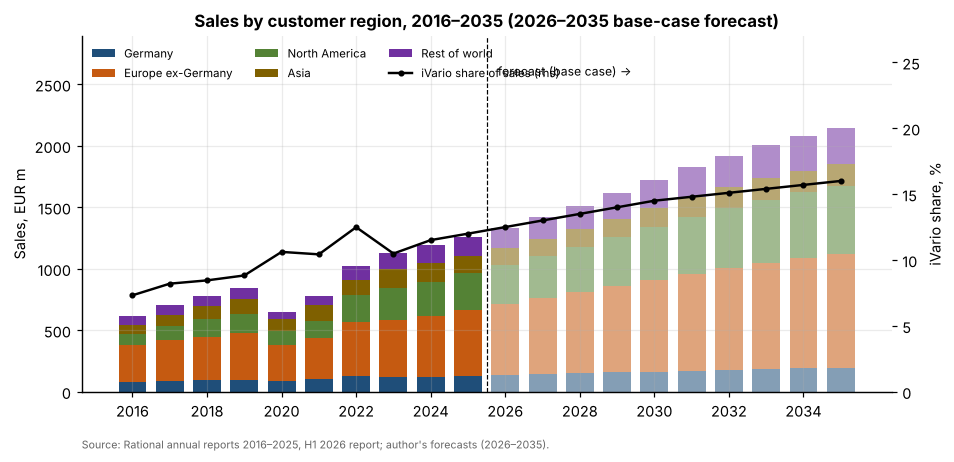

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
years = list(M.HIST) + list(M.YEARS)
REGB = FC["Base"][1]
stack = pd.concat([RH.T, REGB], axis=1)[years]
bottom = np.zeros(len(years))
hist_mask = np.array([y <= 2025 for y in years])
for i, reg in enumerate(M.REGIONS):
    v = stack.loc[reg].values
    ax.bar(np.array(years)[hist_mask], v[hist_mask], bottom=bottom[hist_mask], color=PALETTE[i], width=0.75, label=reg)
    ax.bar(np.array(years)[~hist_mask], v[~hist_mask], bottom=bottom[~hist_mask], color=PALETTE[i], width=0.75, alpha=0.55)
    bottom += v
ax.axvline(2025.5, color="black", lw=0.8, ls="--"); ax.text(2025.8, bottom.max() * 1.2, "forecast (base case) →", fontsize=8)
ax.set_xticks(range(2016, 2036, 2)); ax.set_ylim(0, bottom.max() * 1.35)
ax2 = ax.twinx()
ivs = pd.concat([PH["iVario"] / s, BASE["iVario share"]])
ax2.plot(ivs.index, ivs.values * 100, color="black", lw=1.6, marker="o", ms=3, label="iVario share of sales (rhs)")
ax2.set_ylabel("iVario share, %"); ax2.set_ylim(0, 27); ax2.grid(False)
ax.set_ylabel("Sales, EUR m"); ax.set_title("Sales by customer region, 2016–2035 (2026–2035 base-case forecast)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7.5, ncol=3, loc="upper left", framealpha=0.95)
source(ax, SRC_AR)
fig.savefig(FIG / "fig_revenue_build.png"); plt.show()

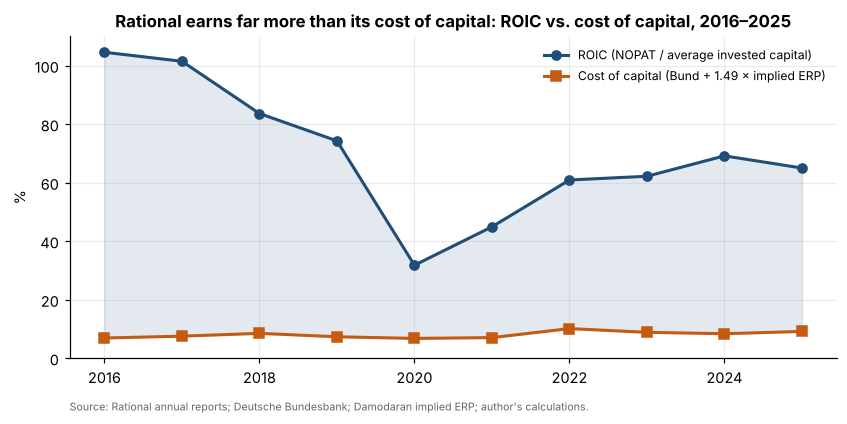

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ROIC.index, ROIC["roic"] * 100, color=PALETTE[0], lw=2, marker="o", label="ROIC (NOPAT / average invested capital)")
ax.plot(ROIC.index, ROIC["ke"] * 100, color=PALETTE[1], lw=2, marker="s", label="Cost of capital (Bund + 1.49 × implied ERP)")
ax.fill_between(ROIC.index, ROIC["ke"] * 100, ROIC["roic"] * 100, color=PALETTE[0], alpha=0.12)
ax.set_ylabel("%"); ax.set_ylim(0, 110); ax.legend(fontsize=8)
ax.set_title("Rational earns far more than its cost of capital: ROIC vs. cost of capital, 2016–2025")
source(ax, "Source: Rational annual reports; Deutsche Bundesbank; Damodaran implied ERP; author's calculations.")
fig.savefig(FIG / "fig_roic_vs_wacc.png"); plt.show()

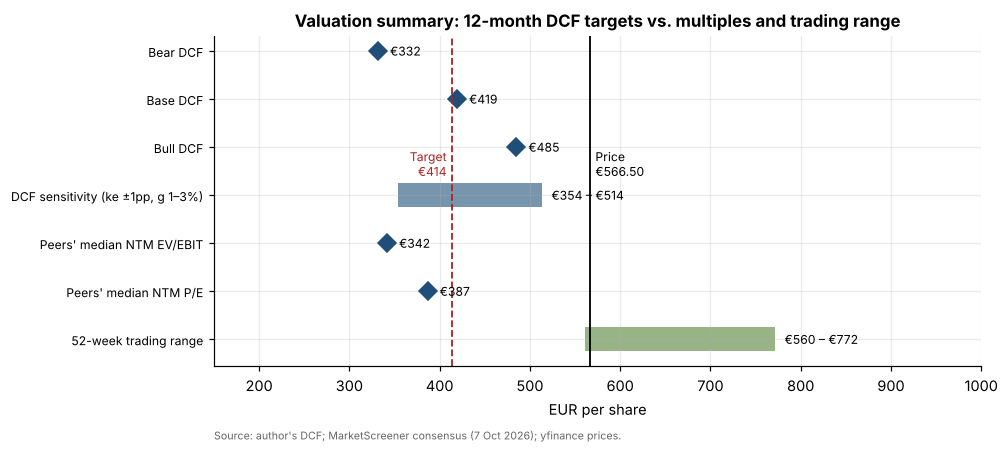

In [11]:
px = pd.read_csv(DATA / "market" / "prices_daily.csv", index_col=0, parse_dates=True)["RAA.DE"].dropna()
hi52, lo52 = px.loc["2025-10-08":"2026-10-07"].max(), px.loc["2025-10-08":"2026-10-07"].min()
bars = [("Bear DCF", VAL["Bear"]["target"], VAL["Bear"]["target"]), ("Base DCF", VAL["Base"]["target"], VAL["Base"]["target"]),
        ("Bull DCF", VAL["Bull"]["target"], VAL["Bull"]["target"]),
        ("DCF sensitivity (ke ±1pp, g 1–3%)", SENS.values.min(), SENS.values.max()),
        ("Peers' median NTM EV/EBIT", IMPL["EV/EBIT at peer median"], IMPL["EV/EBIT at peer median"]),
        ("Peers' median NTM P/E", IMPL["P/E at peer median"], IMPL["P/E at peer median"]),
        ("52-week trading range", lo52, hi52)]
fig, ax = plt.subplots(figsize=(9, 3.9))
for i, (lab, lo, hi) in enumerate(bars):
    if hi - lo < 1:
        ax.plot([lo], [i], "D", color=PALETTE[0], ms=8)
        ax.annotate(f"€{lo:,.0f}", (lo, i), xytext=(8, -3), textcoords="offset points", fontsize=8)
    else:
        ax.barh(i, hi - lo, left=lo, color=PALETTE[2] if "52" in lab else PALETTE[0], alpha=0.6, height=0.5)
        ax.annotate(f"€{lo:,.0f} – €{hi:,.0f}", (hi, i), xytext=(6, -3), textcoords="offset points", fontsize=8)
ax.axvline(MK["price"], color="black", lw=1.2); ax.text(MK["price"] + 6, 2.6, f"Price\n€{MK['price']:,.2f}", fontsize=8)
ax.axvline(TP, color="#B22222", lw=1.2, ls="--"); ax.text(TP - 6, 2.6, f"Target\n€{TP:,.0f}", fontsize=8, color="#B22222", ha="right")
ax.set_yticks(range(len(bars)), [b[0] for b in bars], fontsize=8); ax.invert_yaxis(); ax.set_xlim(150, 1000)
ax.set_xlabel("EUR per share"); ax.set_title("Valuation summary: 12-month DCF targets vs. multiples and trading range")
source(ax, "Source: author's DCF; MarketScreener consensus (7 Oct 2026); yfinance prices.")
fig.savefig(FIG / "fig_valuation_range.png"); plt.show()

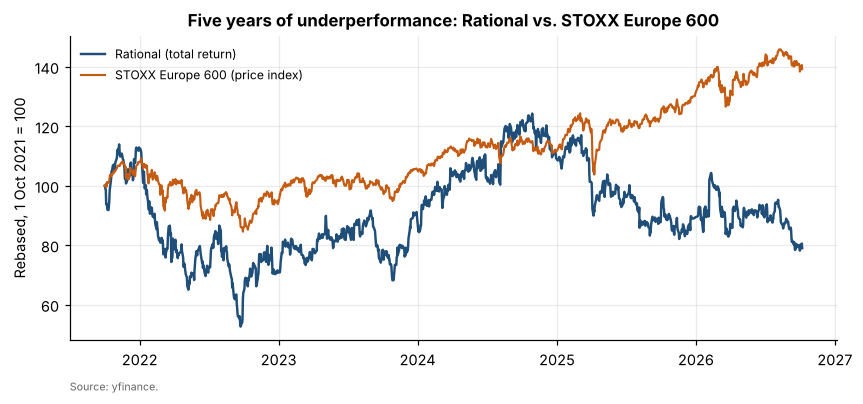

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
p = pd.read_csv(DATA / "market" / "prices_adj_daily.csv", index_col=0, parse_dates=True)[["RAA.DE", "^STOXX"]].loc["2021-10-01":"2026-10-07"].dropna()
rb = p / p.iloc[0] * 100
ax.plot(rb.index, rb["RAA.DE"], color=PALETTE[0], lw=1.6, label="Rational (total return)")
ax.plot(rb.index, rb["^STOXX"], color=PALETTE[1], lw=1.4, label="STOXX Europe 600 (price index)")
ax.set_ylabel("Rebased, 1 Oct 2021 = 100"); ax.legend(fontsize=8)
ax.set_title("Five years of underperformance: Rational vs. STOXX Europe 600")
source(ax, "Source: yfinance.")
fig.savefig(FIG / "fig_share_price.png"); plt.show()

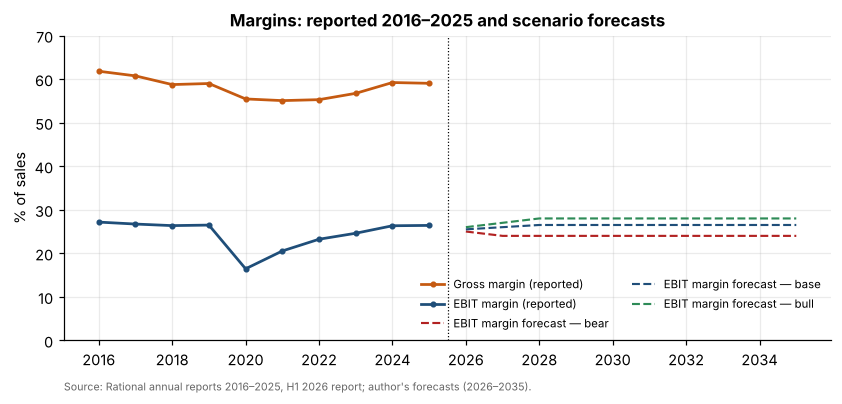

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
em = pd.concat([HIST["EBIT margin"], BASE["EBIT margin"]])
gm = HIST["Gross margin"]
ax.plot(gm.index, gm * 100, color=PALETTE[1], lw=1.8, marker="o", ms=3, label="Gross margin (reported)")
ax.plot(HIST.index, HIST["EBIT margin"] * 100, color=PALETTE[0], lw=1.8, marker="o", ms=3, label="EBIT margin (reported)")
for s_, c in [("Bear", "#B22222"), ("Base", PALETTE[0]), ("Bull", "#2E8B57")]:
    ax.plot(FC[s_][0].index, FC[s_][0]["EBIT margin"] * 100, color=c, lw=1.4, ls="--", label=f"EBIT margin forecast — {s_.lower()}")
ax.axvline(2025.5, color="black", lw=0.8, ls=":"); ax.set_xticks(range(2016, 2036, 2))
ax.set_ylabel("% of sales"); ax.set_ylim(0, 70); ax.legend(fontsize=7.5, ncol=2, loc="lower right")
ax.set_title("Margins: reported 2016–2025 and scenario forecasts")
source(ax, SRC_AR)
fig.savefig(FIG / "fig_margins.png"); plt.show()

## 7. Save outputs for the report

In [14]:
HIST.to_csv(DATA / "out_history_summary.csv")
for s_ in M.WEIGHTS:
    FC[s_][0].to_csv(DATA / f"out_forecast_{s_.lower()}.csv")
pd.concat({"Sales": FC["Base"][1], "iVario": FC["Base"][2], "iCombi": FC["Base"][3]}).to_csv(DATA / "out_revenue_build_base.csv")
SUMMARY.to_csv(DATA / "out_scenarios.csv"); SENS.to_csv(DATA / "out_sensitivity.csv"); VS_CONS.to_csv(DATA / "out_vs_consensus.csv")
CT.to_csv(DATA / "out_comps.csv"); ROIC.to_csv(DATA / "out_roic.csv")
json.dump({**{k: v for k, v in MK.items()}, "target": TP, "rating": RATING, "upside": UP, "implied_ke": IMPLIED_KE,
           "net_cash": ncash_now, "reverse_dcf": REVERSE, "peer_median": MED, "implied_by_multiples": IMPL, "premium": PREM,
           "hi52": float(hi52), "lo52": float(lo52), "dcf": {s_: {k: float(VAL[s_][k]) for k in ["pv_explicit", "pv_tv", "ev", "equity",
           "value_per_share", "dps_next12m", "target", "tv_share_of_ev"]} for s_ in VAL}},
          open(DATA / "out_valuation.json", "w"), indent=2, default=float)